Q1: Modeling and Analyzing Neural Spike Patterns
A. Constructing the Models and Assumptions

I simulated 5 seconds of spike times for three types of neurons. I chose parameters so that all three neurons fire at about the same average speed (~10 spikes per second), so I can compare their patterns fairly.

1. Regular neuron: This model is deterministic (no randomness). It fires at a fixed interval of 0.1 seconds.

2. Irregular neuron: This model is stochastic (random). Each waiting time between spikes is picked randomly from an exponential distribution (rng.exponential) with an average of 0.1 seconds. I chose the exponential distribution because it always gives positive waiting times, with many short gaps and fewer long ones, which fits random firing with no memory of past spikes. I used seed=42 so I get the same results every time I run the notebook.

3. Bursting neuron: This model fires 4 quick spikes in a group (about 0.02 seconds apart) and then waits a longer quiet time (about 0.34 seconds) before the next group. I added small random noise to both waiting times so the bursts are not identical.

To make sure all spike times are valid and in time order, I always add positive waiting times and stop at 5.0 seconds. I also used max() so the random noise never makes an interval zero or negative.

In [38]:
import numpy as np

def run_regular(duration=5.0, isi=0.1):
    if duration <= 0 or isi <= 0:
        return np.array([])
    # Add tiny 1e-12 so duration itself (5.0 s) is included
    return np.arange(isi, duration + 1e-12, isi)

regular_spikes = run_regular(5.0, isi=0.1)
print("Count:", len(regular_spikes))
print("First 5 spikes:", regular_spikes[:5])



Count: 50
First 5 spikes: [0.1 0.2 0.3 0.4 0.5]


In [39]:
def run_irregular(duration=5.0, scale=0.1, seed=42):
    # Edge-case guard: return empty array if duration or scale is not positive
    if duration <= 0 or scale <= 0:
        return np.array([])

    # Create a random generator with a fixed seed for reproducible results
    rng = np.random.default_rng(seed)

    spikes = []         # Empty list to store spike times
    current_time = 0.0  # Start clock at 0 seconds

    while True:
        # Draw a random positive waiting time (mean = scale), ISI = Inter-Spike Interval
        # exponential distribution = many short gaps, fewer long gaps
        isi = rng.exponential(scale=scale)
        current_time += isi  # Move clock forward

        # Stop if we pass the recording window
        if current_time > duration:
            break

        spikes.append(current_time)  # Save valid spike time

    # Convert list to NumPy array for easy calculations later
    return np.array(spikes)


irregular_spikes = run_irregular(5.0, scale=0.1, seed=42)

print("Count:", len(irregular_spikes))
# Quick sanity check: print just the first 5 spikes (rounded to 3 decimals) to verify the values
print("First 5 spikes:", np.round(irregular_spikes[:5], 3))

Count: 60
First 5 spikes: [0.24  0.474 0.713 0.74  0.749]


In [40]:
def run_bursting(
    duration=5.0,
    spikes_per_burst=4,  # I chose 4 spikes per burst so each group of spikes is easy to see
    intra_burst_mean=0.02,  # Short interval within a burst (20 ms)
    inter_burst_mean=0.34,  # Long quiet interval between bursts (340 ms)
    seed=42,
):
    # Edge-case guard: return empty array if duration is not positive
    if duration <= 0:
        return np.array([])

    rng = np.random.default_rng(seed)
    spikes_burst = []
    current_time = 0.05  # Start after t = 0 for consistency with the other neurons and clearer plotting

    while current_time <= duration:
        # 1. Fire a rapid burst of 4 spikes
        for i in range(spikes_per_burst):
            if current_time > duration:
                break
            spikes_burst.append(current_time)
            # Add a short gap only between spikes in the burst (not after the last spike)
            if i < spikes_per_burst - 1:
                # Keep the interval positive (at least 2 ms) even if random noise is negative. 0.002 is for safety
                intra_isi = max(0.002, intra_burst_mean + rng.normal(0, 0.003))
                current_time += intra_isi

        # 2. Add a long quiet interval before the next burst starts
        # Keep the quiet gap between bursts positive (at least 50 ms) even if random noise is negative
        inter_isi = max(0.05, inter_burst_mean + rng.normal(0, 0.015))
        current_time += inter_isi

    return np.array(spikes_burst)


bursting_spikes = run_bursting(5.0, seed=42)

print("Count:", len(bursting_spikes))
# Quick sanity check: print the first 8 spikes (2 bursts) to see the gap between bursts
print("First 8 spikes:", np.round(bursting_spikes[:8], 3))

Count: 52
First 8 spikes: [0.05  0.071 0.088 0.11  0.464 0.478 0.494 0.515]


B. Investigating the Firing Patterns

To compare the three neurons, I used a spike raster plot (to see the timing over the 5 seconds), and I chose a summary table (mean rate, mean ISI(Inter-Spike Interval), median ISI, SD, CV(SD / Mean)) plus ISI histograms to compare the spread of the waiting times.

1. Spikes over time and what the raster plot shows:
The raster plot clearly shows the timing differences. The regular neuron fires evenly like a clock, the irregular neuron fires at random times with unpredictable gaps, and the bursting neuron fires in tight groups of 4 spikes with quiet gaps between them.

2. What the ISI distributions show:
The ISIs show the waiting times between spikes. In the histograms, the regular neuron has one single bar at 0.1 s. The irregular neuron has many short intervals and fewer long ones (an exponential shape). The bursting neuron has two separate groups: very short intervals (~0.02 s) inside bursts and long intervals (~0.34 s) between bursts.

3. Can mean firing rate alone distinguish them?
No. As shown in the summary table, all three neurons have almost the same mean firing rate (around 10-12 Hz), so the average rate alone cannot tell them apart.

4. Additional statistics that help:
The median ISI, standard deviation (SD), and CV (SD / Mean) distinguish the neurons well. The SD shows how spread out the intervals are: zero for regular, moderate for irregular, and largest for bursting because it mixes very short and long gaps. The CV gives a clear scale: 0 for regular, close to 1 for irregular, and clearly above 1 for bursting. Also, in the bursting neuron, the median ISI is much smaller than the mean ISI because most intervals are inside bursts.

In [41]:
import pandas as pd

# Put the 3 spike arrays in a dictionary so I can loop over them easily
neurons = {
    "Regular": regular_spikes,
    "Irregular": irregular_spikes,
    "Bursting": bursting_spikes,
}

summary_rows = []
isis_dict = {}  # Save the ISIs so I can plot them in the next step

for name, spikes in neurons.items():
    isis = np.diff(spikes)  # Calculate time gaps between consecutive spikes
    isis_dict[name] = isis

    mean_isi = np.mean(isis)
    std_isi = np.std(isis)

    summary_rows.append({
        "Neuron": name,
        "Spikes": len(spikes),
        "Mean Rate (Hz)": round(len(spikes) / 5.0, 2),
        "Mean ISI (s)": round(mean_isi, 4),
        "Median ISI (s)": round(np.median(isis), 4),
        "SD ISI (s)": round(std_isi, 4),
        "CV (SD/Mean)": round(std_isi / mean_isi, 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Neuron,Spikes,Mean Rate (Hz),Mean ISI (s),Median ISI (s),SD ISI (s),CV (SD/Mean)
0,Regular,50,10.0,0.1000,0.1000,0.0000,0.000
1,Irregular,60,12.0,0.0796,0.0453,0.0777,0.976
2,Bursting,52,10.4,0.0962,0.0213,0.1371,1.425


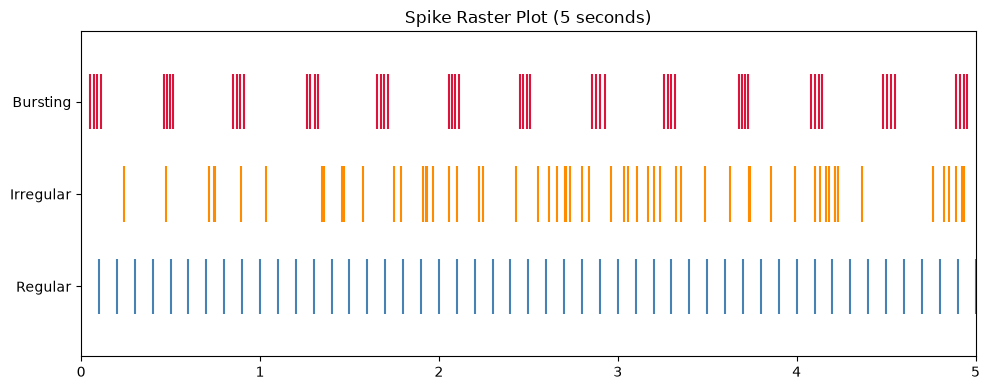

In [42]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)  # Create figures folder if it does not exist

fig, ax = plt.subplots(figsize=(10, 4))

# Draw vertical lines for every spike of each neuron on its own row
ax.eventplot(
    [regular_spikes, irregular_spikes, bursting_spikes],
    lineoffsets=[0, 1, 2],  # Place each neuron on its own row (y = 0, 1, 2)
    linelengths=0.6,  # Height of each vertical spike line
    colors=["steelblue", "darkorange", "crimson"],
)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(["Regular", "Irregular", "Bursting"])
ax.set_xlim(0, 5.0)  # Show the exact 0 to 5 second recording window on the x-axisax.set_xlabel("Time (seconds)")
ax.set_title("Spike Raster Plot (5 seconds)")

plt.tight_layout()  # Adjust spacing so labels do not get cut off
plt.savefig("figures/q1_raster_plot.png", dpi=150)  # Save high-quality image before showing
plt.show()          # Display the plot below this cell

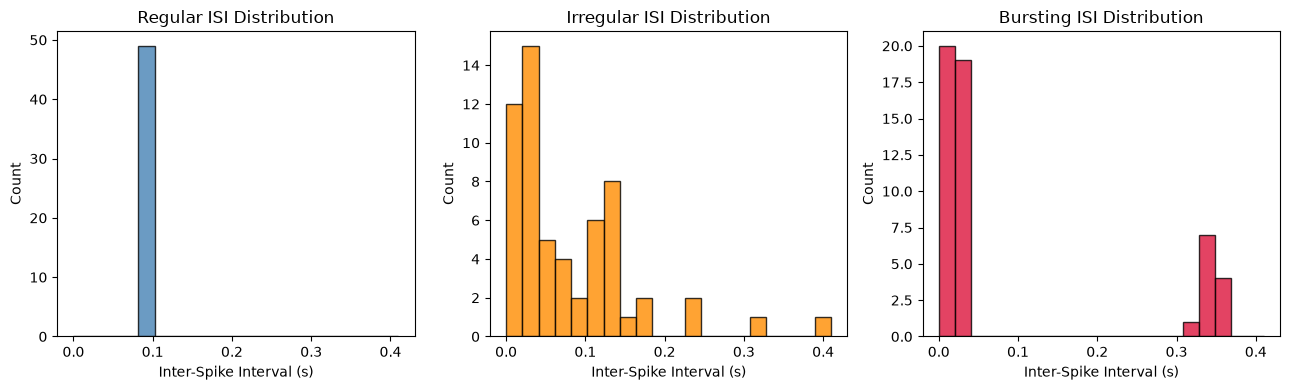

In [43]:
# Create 3 side-by-side plots that share the same x-axis for fair comparison
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)

# Create 20 equal bins (21 edges) from 0 to 0.41 s so 0.1 s falls inside one bin
bins = np.linspace(0, 0.41, 21)
colors = ["steelblue", "darkorange", "crimson"]

# Loop through each subplot, neuron's ISIs, and color together using zip
for ax, (name, isis), color in zip(axes, isis_dict.items(), colors):
    # Plot histogram with black bar outlines and slight transparency
    ax.hist(isis, bins=bins, color=color, edgecolor="black", alpha=0.8)
    ax.set_title(f"{name} ISI Distribution")  # Set title for this neuron
    ax.set_xlabel("Inter-Spike Interval (s)")  # Label x-axis
    ax.set_ylabel("Count")  # Label y-axis

plt.tight_layout()  # Adjust spacing so labels do not overlap
plt.savefig("figures/q1_isi_histograms.png", dpi=150)  # Save image for submission
plt.show()

C. Testing My Assumptions

To make sure my code really implements the models I intended (and does not just run without errors), I ran three checks:

1. Temporal behavior: I checked all three neurons to make sure all spike times are inside (0, 5.0] seconds and all ISIs are strictly positive (ordered in time). I also checked that the regular neuron has constant 0.1 s intervals. All checks returned True.

2. Statistical properties: I focused on the irregular neuron because the regular neuron has no randomness (SD = 0), while the exponential model has a clear theoretical rule: Mean = SD = scale, so CV should stay near 1.0. Over a 200-second simulation with scale = 0.05, 0.10, and 0.20 s, both the mean ISI and SD grew together (0.050, 0.102, 0.202 s) and the CV stayed near 1.0 (1.01-1.02).

3. Edge case and reproducibility: For a 0-second recording, all three models returned 0 spikes without errors. Running the irregular model twice with seed=42 produced identical spike times (True), while using seed=99 produced different results (False).

In [44]:
# Check 1 (Temporal behavior):
# Verify that all spikes are within (0, 5.0] s (all spikes > 0 and <= 5.0 s), all ISIs are positive,
# and the regular neuron has constant 0.1 s intervals.
check1_passed = True

for name, spikes in neurons.items():
    isis = np.diff(spikes)

    in_window = np.all((spikes > 0) & (spikes <= 5.0))  # All spikes > 0 and <= 5.0 s?
    positive_isis = np.all(isis > 0)  # All intervals strictly positive?
    check1_passed = check1_passed and in_window and positive_isis

    print(f"{name}: inside (0, 5.0]s = {in_window}, all ISIs > 0 = {positive_isis}")

# Check that all intervals of the regular neuron are equal to 0.1 s
regular_constant = np.allclose(np.diff(regular_spikes), 0.1)
check1_passed = check1_passed and regular_constant
print("Regular neuron has constant 0.1 s intervals:", regular_constant)
print("Check 1 (Temporal) passed:", check1_passed)

Regular: inside (0, 5.0]s = True, all ISIs > 0 = True
Irregular: inside (0, 5.0]s = True, all ISIs > 0 = True
Bursting: inside (0, 5.0]s = True, all ISIs > 0 = True
Regular neuron has constant 0.1 s intervals: True
Check 1 (Temporal) passed: True


In [45]:
# Check 2 (Statistical properties - Irregular neuron):
# I focused on the irregular neuron here because regular has no randomness (SD = 0),
# while in an exponential distribution, SD equals the mean, so CV (SD / Mean) should stay near 1.0.
# When I increase the 'scale' (average gap), both Mean ISI and SD should grow together.
means, sds, cvs = [], [], []

# Run for 200 seconds (long recording) so the statistics are stable
for scale_val in [0.05, 0.10, 0.20]:
    test_spikes = run_irregular(duration=200.0, scale=scale_val, seed=42)
    test_isis = np.diff(test_spikes) # Calculate gaps between spikes
    mean_val = np.mean(test_isis)
    sd_val = np.std(test_isis)
    cv_val = sd_val / mean_val  # In an exponential distribution SD = Mean, so CV = SD / Mean stays near 1.0
    means.append(mean_val)
    sds.append(sd_val)
    cvs.append(cv_val)
    print(f"scale={scale_val:.2f} -> Mean ISI={mean_val:.3f}s, SD={sd_val:.3f}s, CV={cv_val:.2f}")

# Dynamically check that Mean & SD grew with scale and CV stayed near 1.0
means_grew = means[0] < means[1] < means[2]
sds_grew = sds[0] < sds[1] < sds[2]
cv_near_1 = all(0.9 <= c <= 1.1 for c in cvs)
print("Check 2 (Statistical) passed:", means_grew and sds_grew and cv_near_1)

scale=0.05 -> Mean ISI=0.050s, SD=0.050s, CV=1.01
scale=0.10 -> Mean ISI=0.102s, SD=0.103s, CV=1.01
scale=0.20 -> Mean ISI=0.202s, SD=0.206s, CV=1.02
Check 2 (Statistical) passed: True


In [46]:
# Check 3 (Edge case & Reproducibility):
# 1. Edge case: a 0-second recording should return 0 spikes without errors.
# 2. Reproducibility: the same seed (42) must produce identical spike times.
edge_ok = (len(run_regular(0.0)) == 0) and (len(run_irregular(0.0, 0.1)) == 0) and (len(run_bursting(0.0)) == 0)
print("Edge case (duration = 0 s) -> all 0 spikes:", edge_ok)

# 2. Reproducibility check (same seed vs. different seed)
irr_run1 = run_irregular(5.0, 0.1, seed=42)
irr_run2 = run_irregular(5.0, 0.1, seed=42)
irr_diff = run_irregular(5.0, 0.1, seed=99)

same_seed_ok = np.array_equal(irr_run1, irr_run2)
diff_seed_ok = not np.array_equal(irr_run1, irr_diff)

print("Same seed (42) identical:", same_seed_ok)
print("Different seed (42 vs 99) gives different spikes:", diff_seed_ok)
print("Check 3 (Edge case & Seed) passed:", edge_ok and same_seed_ok and diff_seed_ok)

Edge case (duration = 0 s) -> all 0 spikes: True
Same seed (42) identical: True
Different seed (42 vs 99) gives different spikes: True
Check 3 (Edge case & Seed) passed: True
